<a href="https://colab.research.google.com/github/runkael2/BA305-A6-Team-Project/blob/main/Rachael/FinalForest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
# Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
# used to turn categorical into dummies
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline


In [19]:
url = "https://raw.githubusercontent.com/runkael2/BA305-A6-Team-Project/refs/heads/main/UK_GenderPayGap_NoYears%20(revised).csv"
paygap_df = pd.read_csv(url)
display(paygap_df.head(5))




,EmployerID,Region,Industry,Size,Average of DiffMeanHourlyPercent,Average of DiffMedianHourlyPercent,Average of DiffMeanBonusPercent,Average of DiffMedianBonusPercent,Average of MaleBonusPercent,Average of FemaleBonusPercent,Average of MaleLowerQuartile,Average of FemaleLowerQuartile,Average of FemaleTopQuartile,Average of MaleTopQuartile,Average of MaleLowerMiddleQuartile,Average of FemaleLowerMiddleQuartile,Average of MaleUpperMiddleQuartile,Average of FemaleUpperMiddleQuartile
0,4,Southampton,Health/SocialWork,500 to 999,-2.74,-5.440,20.640000,-21.880000,11.700,8.460,57.920,42.080,44.86,55.14,75.12,24.88,68.520,31.480
1,5,Leicester,Manufacturing,250 to 499,13.60,6.475,69.033333,40.433333,28.375,26.775,79.000,21.000,10.50,89.50,90.75,9.25,88.250,11.750
2,6,Bristol,AdministrativeServices,1000 to 4999,9.15,9.475,9.150000,9.450000,75.250,68.750,43.825,56.175,26.00,74.00,43.25,56.75,64.175,35.825
3,7,Stockport,Manufacturing,250 to 499,4.50,-5.220,43.980000,-8.960000,10.200,8.600,65.000,35.000,22.20,77.80,66.20,33.80,60.000,40.000
4,8,Reading,Wholesale & Retail Trade,500 to 999,5.32,4.460,50.820000,34.820000,92.400,89.800,60.000,40.000,38.80,61.20,62.60,37.40,60.000,40.000


In [20]:
features = ["Industry", "Region", "Size"]
target = "Average of DiffMeanHourlyPercent"

In [21]:
# Hold out 20% for the final test. Split the remaining 80% into train and validation.
development, test = train_test_split(paygap_df, test_size=0.20, random_state=42)
train, val = train_test_split(development, test_size=0.25, random_state=42)

print(f"Train: {len(train):,} | Validation: {len(val):,} | Test: {len(test):,}")

Train: 7,648 | Validation: 2,550 | Test: 2,550


In [22]:
ccp_alpha = 0.15
depth = 110
leaf_size = 8

forest = make_pipeline(
    OneHotEncoder(handle_unknown="ignore"),
    RandomForestRegressor(
        n_estimators=500,
        max_depth=depth,
        min_samples_leaf=leaf_size,
        ccp_alpha=ccp_alpha,
        random_state=0,
        n_jobs=-1,
    ),
)
forest.fit(train[features], train[target])
val_predictions = forest.predict(val[features])
y_val = val[target]

# Give every validation employer the same training-median prediction.
val_baseline_errors = y_val - train[target].median()

# RMSE is the square root of the mean squared error.
forest_val_rmse = mean_squared_error(y_val, val_predictions) ** 0.5
baseline_val_rmse = (val_baseline_errors ** 2).mean() ** 0.5

print(f"Depth {depth} | Leaf size {leaf_size}")
print(f"Forest validation MAE:    {mean_absolute_error(y_val, val_predictions):.2f} pp")
print(f"Baseline validation MAE:  {val_baseline_errors.abs().mean():.2f} pp")
print(f"Forest validation RMSE:   {forest_val_rmse:.2f} pp")
print(f"Baseline validation RMSE: {baseline_val_rmse:.2f} pp")

# Baseline MAE/RMSE is how far off you are, on average,
# when you predict the same training-set median pay gap for every validation employer.

Depth 110 | Leaf size 8
Forest validation MAE:    9.63 pp
Baseline validation MAE:  10.41 pp
Forest validation RMSE:   13.15 pp
Baseline validation RMSE: 13.80 pp


In [23]:
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Combine training and validation now that the settings are chosen.
final_train = pd.concat([train, val], ignore_index=True)

# Copy the selected settings and fit a fresh pipeline.
final_forest = clone(forest)
final_forest.fit(final_train[features], final_train[target])

# Predict each test employer's average annual median pay gap.
y_test = test[target]
test_predictions = final_forest.predict(test[features])

forest_test_mae = mean_absolute_error(y_test, test_predictions)
forest_test_rmse = mean_squared_error(y_test, test_predictions) ** 0.5

# Baseline: predict the median target from the combined fitting data.
baseline_prediction = final_train[target].median()
baseline_errors = y_test - baseline_prediction
baseline_test_mae = baseline_errors.abs().mean()
baseline_test_rmse = (baseline_errors ** 2).mean() ** 0.5

print(f"Test employers: {len(test):,}")
print(f"Forest test MAE:    {forest_test_mae:.2f} pp")
print(f"Baseline test MAE:  {baseline_test_mae:.2f} pp")
print(f"MAE reduction:      {baseline_test_mae - forest_test_mae:.2f} pp")
print()
print(f"Forest test RMSE:   {forest_test_rmse:.2f} pp")
print(f"Baseline test RMSE: {baseline_test_rmse:.2f} pp")
print(f"RMSE reduction:     {baseline_test_rmse - forest_test_rmse:.2f} pp")

Test employers: 2,550
Forest test MAE:    9.71 pp
Baseline test MAE:  10.54 pp
MAE reduction:      0.83 pp

Forest test RMSE:   13.80 pp
Baseline test RMSE: 14.46 pp
RMSE reduction:     0.66 pp


In [24]:
import pandas as pd
from sklearn.model_selection import KFold, cross_validate

# Shuffle the development employers into five reproducible folds.
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Fit a fresh copy of your existing pipeline in each fold.
scores = cross_validate(
    forest,
    development[features],
    development[target],
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
    },
)

# Scikit-learn returns negative errors so higher scores rank better.
# Flip the signs back to report MAE and RMSE in percentage points.
fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE (pp)": -scores["test_mae"],
    "RMSE (pp)": -scores["test_rmse"],
})

display(fold_results.round(2))
print(f"Mean CV MAE:  {fold_results['MAE (pp)'].mean():.2f} pp")
print(f"Mean CV RMSE: {fold_results['RMSE (pp)'].mean():.2f} pp")

,Fold,MAE (pp),RMSE (pp)
0,1,9.53,13.10
1,2,9.74,13.40
2,3,9.65,13.87
3,4,9.70,13.15
4,5,9.40,12.65


Mean CV MAE:  9.61 pp
Mean CV RMSE: 13.23 pp


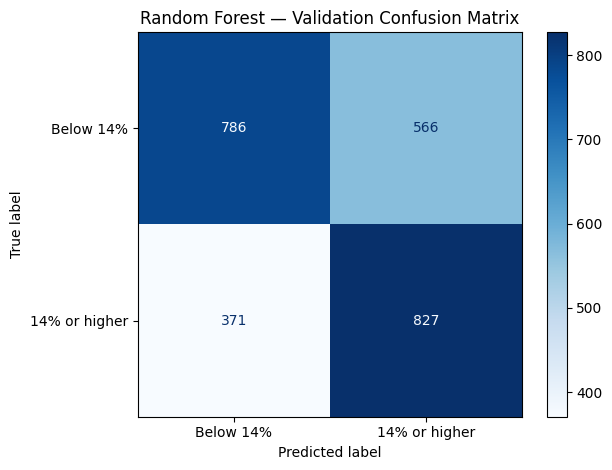

,Metric,Random forest,Training-median baseline
0,MAE,9.63 pp,10.41 pp
1,RMSE,13.15 pp,13.80 pp
2,Recall,69.0%,—
3,Precision,59.4%,—


In [28]:
# Model Evaluation Time!

# Care most about RECALL & Precision

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cutoff = 14  # flag pay gaps of 14% or higher (above avg)

actual_high = y_val >= cutoff
predicted_high = val_predictions >= cutoff

ConfusionMatrixDisplay.from_predictions(
    actual_high,
    predicted_high,
    labels=[False, True],
    display_labels=[f"Below {cutoff}%", f"{cutoff}% or higher"],
    cmap="Blues",
    values_format="d",
)
plt.title("Random Forest — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

correctly_flagged = (actual_high & predicted_high).sum()

recall = (
    f"{correctly_flagged / actual_high.sum():.1%}"
    if actual_high.any()
    else "Undefined (no actual high gaps)"
)
precision = (
    f"{correctly_flagged / predicted_high.sum():.1%}"
    if predicted_high.any()
    else "Undefined (no employers flagged)"
)

display(pd.DataFrame({
    "Metric": ["MAE", "RMSE", "Recall", "Precision"],
    "Random forest": [
        f"{mean_absolute_error(y_val, val_predictions):.2f} pp",
        f"{forest_val_rmse:.2f} pp",
        recall,
        precision,
    ],
    "Training-median baseline": [
        f"{val_baseline_errors.abs().mean():.2f} pp",
        f"{baseline_val_rmse:.2f} pp",
        "—",
        "—",
    ],
}))

# FOr Validation

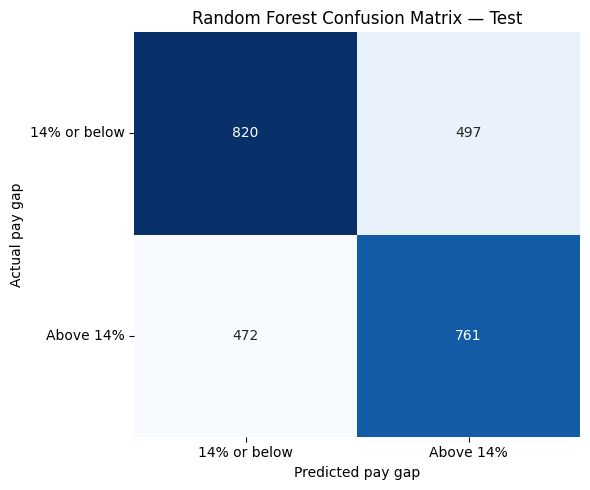

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Flag gaps strictly above 14%.
actual_high = y_test > 14
predicted_high = test_predictions > 14

cm = confusion_matrix(actual_high, predicted_high, labels=[False, True])
labels = ["14% or below", "Above 14%"]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt=",d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    cbar=False,
    ax=ax,
)

ax.set_title("Random Forest Confusion Matrix — Test")
ax.set_xlabel("Predicted pay gap")
ax.set_ylabel("Actual pay gap")
ax.tick_params(axis="y", labelrotation=0)
plt.tight_layout()
plt.show()

# For Test